# SMLM Background Noise-Map Library & DECODE Simulator Pipeline

This notebook constructs the modular **Experimental Background ("Noise Map") Extraction, Disk Caching, Augmentation, and DECODE Simulation Pipeline** for our ONI Nanoimager recordings.

### Pipeline Architecture
1. **Curated Experimental TIFF Dataset Registry:**  
   Hardcoded list of all 7 multi-frame SMLM `.tif` recordings that contain sufficient temporal depth ($\ge 50$ frames) across both low-density (`F3`) and high-density (`F8`) and low-autofluorescence (`SealA`) vs. high-autofluorescence (`SealG`) imaging conditions, alongside their exact frame counts (`1826` or `174` frames).
2. **Sliding-Window Smooth Background Extraction & Disk Caching (`localisation_workflow/vae_background/noise_maps/`):**  
   - Converts raw 16-bit sCMOS ADU frames from the active right channel ($684 \times 428\text{ px}$) into physical photon units ($I_{\mathrm{phot}} = (\mathrm{ADU} - 400.0) \times 0.46 / 0.80$).
   - Extracts 50-frame temporal median maps across strided temporal windows along each movie and removes stationary fiducial beads / persistent emitter clusters via **Option 2** (25th-percentile spatial baseline + Poisson/Laplace & left-tail quantile $\sigma_{\mathrm{bg}}$ + $\kappa\sigma$ outlier masking with $r = 3\text{ px}$ disk dilation + Normalized Gaussian Convolution inpainting).
   - Saves each extracted $684 \times 428$ smooth background map to `localisation_workflow/vae_background/noise_maps/*.npy` (plus `manifest.json`) so full-FOV arrays never need to reside simultaneously in RAM.
3. **Memory-Mapped 3-Stage Augmentation Engine (`BackgroundPatchAugmentor`):**  
   - Reads only the required spatial window from disk via NumPy memory-mapping (`mmap_mode='r'`).
   - Applies our selected augmentation space: **(i) Coin-Flip Horizontal Reflection + Continuous Rotation ($\theta \sim \mathcal{U}(0^\circ, 360^\circ)$)** inside a $\lceil \sqrt{2}\,P \rceil = 142 \times 142$ source window, **(ii) Anisotropic Affine Warp** ($s_x, s_y \in [0.75, 1.35]$, shear $\psi_x, \psi_y \in [-15^\circ, +15^\circ]$), and **(iii) Normalised Convex Combination (Mixup)** of $K$ patches with variance-preserving re-normalisation and physical photon re-scaling.
4. **End-to-End Verification & DECODE Simulation:**  
   - Visualises the disk-cached noise maps across all 7 datasets, their temporal background decay curves, augmented $100 \times 100$ background patches (both physical and zero-mean/unit-variance normalised for VAE training), and full 3D spline PSF DECODE simulated frames.

In [2]:
import json
from pathlib import Path
import numpy as np
import tifffile
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.ndimage import (
    gaussian_filter, binary_dilation,
    percentile_filter, rotate, affine_transform
)
import decode.utils.param_io
import decode.simulation.background
import decode.simulation.simulator
from decode.neuralfitter.train.random_simulation import setup_random_simulation

project = Path('/Users/rohan/Documents/projects/mphys')
workflow_dir = project / 'localisation_workflow'
noise_maps_dir = workflow_dir / 'vae_background' / 'noise_maps'
noise_maps_dir.mkdir(parents=True, exist_ok=True)

# ONI Nanoimager sCMOS camera parameters (convert ADU -> physical photons)
CAMERA_BASELINE_ADU = 400.0
CAMERA_E_PER_ADU = 0.46
CAMERA_QE = 0.80
ADU_TO_PHOTONS = CAMERA_E_PER_ADU / CAMERA_QE  # 0.575 photons / ADU (1.739 ADU / photon)

# Hardcoded registry of experimental .tif recordings with sufficient frames (>= 50 frames)
# (Excludes 10-frame *_TM.tif / *_locs_*.tif snapshots, bead z-stacks, and duplicate corrected.tif)
TIFF_DATASETS = [
    {
        'id': 'LowDensity_SealG_F3',
        'rel_path': 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif',
        'n_frames': 1826,
        'density': 'low',
        'seal': 'SealG'
    },
    {
        'id': 'LowDensity_SealG_F3_1',
        'rel_path': 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3_1.tif',
        'n_frames': 174,
        'density': 'low',
        'seal': 'SealG'
    },
    {
        'id': 'LowDensity_SealA_F3',
        'rel_path': 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealA_F3.tif',
        'n_frames': 1826,
        'density': 'low',
        'seal': 'SealA'
    },
    {
        'id': 'HighDensity_SealG_F8',
        'rel_path': 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealG_F8.tif',
        'n_frames': 1826,
        'density': 'high',
        'seal': 'SealG'
    },
    {
        'id': 'HighDensity_SealG_F8_1',
        'rel_path': 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealG_F8_1.tif',
        'n_frames': 174,
        'density': 'high',
        'seal': 'SealG'
    },
    {
        'id': 'HighDensity_SealA_F8',
        'rel_path': 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealA_F8.tif',
        'n_frames': 1826,
        'density': 'high',
        'seal': 'SealA'
    },
    {
        'id': 'HighDensity_SealA_F8_1',
        'rel_path': 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealA_F8_1.tif',
        'n_frames': 174,
        'density': 'high',
        'seal': 'SealA'
    },
]

print(f'Registered {len(TIFF_DATASETS)} experimental TIFF datasets (total frames = {sum(d["n_frames"] for d in TIFF_DATASETS)}):')
for d in TIFF_DATASETS:
    p = project / d['rel_path']
    assert p.exists(), f'Missing file: {p}'
    print(f"  - {d['id']:<24} | frames: {d['n_frames']:>4} | density: {d['density']:<4} | {d['rel_path']}")

Registered 7 experimental TIFF datasets (total frames = 7826):
  - LowDensity_SealG_F3      | frames: 1826 | density: low  | data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif
  - LowDensity_SealG_F3_1    | frames:  174 | density: low  | data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3_1.tif
  - LowDensity_SealA_F3      | frames: 1826 | density: low  | data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealA_F3.tif
  - HighDensity_SealG_F8     | frames: 1826 | density: high | data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealG_F8.tif
  - HighDensity_SealG_F8_1   | frames:  174 | density: high | data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealG_F8_1.tif
  - HighDensity_SealA_F8     | frames: 1826 | density: high | data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealA_F8.tif
  - HighDensity_SealA_F8_1   | frames:  174 | density: hi

## 1. Extract Smooth Background ("Noise") Maps & Cache to `localisation_workflow/vae_background/noise_maps/`

To capture both spatial illumination structure and temporal background evolution (e.g., autofluorescence photobleaching over a 2000-frame acquisition) without holding gigabytes of raw TIFF stacks in memory:
- For each registered `.tif` file, we step a **50-frame sliding window** across the recording (`window_size = 50`, `stride = 200` for 1826-frame movies $\rightarrow 9$ temporal windows; `stride = 60` for 174-frame continuation movies $\rightarrow 3$ temporal windows, yielding **45 full-FOV $684 \times 428$ smooth background maps** in total).
- Each 50-frame block is converted to physical photon units on the active right channel ($684 \times 428\text{ px}$), collapsed to its temporal median $M(y, x)$, and filtered with **Option 2** (`extract_bg_option2`) to inpaint stationary fiducial beads and high-duty-cycle fluorophore clusters.
- Every extracted smooth background map $B_{\mathrm{smooth}}(y, x)$ is saved immediately to `localisation_workflow/vae_background/noise_maps/<dataset_id>_f<start>_to_f<end>.npy` (as `float32`, $\sim 1.14\text{ MB}$ per map) along with summary statistics in `manifest.json`.

In [3]:
def extract_bg_option2(
    t_med: np.ndarray,
    n_frames: int = 50,
    kappa: float = 2.5,
    dilate_px: int = 3,
    inpaint_sigma: float = 7.0,
    smooth_sigma: float = 2.5,
):
    """
    Option 2 background extractor (Section 7 of 03_background_gen.ipynb):
      1. Local 25th-percentile spatial baseline P_25(y, x) over a 25x25 neighborhood.
      2. Hybrid noise scale sigma_bg(y, x) = max(sigma_t_med,Poisson, median(sigma_left)).
      3. Outlier detection (M - mu_bg > kappa * sigma_bg) + binary disk dilation (r = 3 px).
      4. Normalized Gaussian Convolution inpainting (sigma = 7.0 px) + final smoothing (sigma = 2.5 px).
    """
    p25_local = percentile_filter(t_med, percentile=25, size=25)
    p05_local = percentile_filter(t_med, percentile=5, size=25)
    sigma_left_local = (p25_local - p05_local) / 0.9704

    sigma_poisson_local = np.sqrt((np.pi / (2.0 * n_frames)) * np.maximum(p25_local, 1.0))
    sigma_bg = np.maximum(sigma_poisson_local, float(np.median(sigma_left_local)))
    mu_bg_local = p25_local + 0.6745 * sigma_bg

    raw_mask = (t_med - mu_bg_local) > (kappa * sigma_bg)
    y_g, x_g = np.ogrid[-dilate_px : dilate_px + 1, -dilate_px : dilate_px + 1]
    disk_struct = (x_g**2 + y_g**2) <= dilate_px**2
    dilated_mask = binary_dilation(raw_mask, structure=disk_struct)

    w = (~dilated_mask).astype(np.float32)
    num_inp = gaussian_filter(t_med * w, sigma=inpaint_sigma, mode='nearest')
    den_inp = gaussian_filter(w, sigma=inpaint_sigma, mode='nearest')
    inpainted_fill = np.where(den_inp > 1e-3, num_inp / np.maximum(den_inp, 1e-3), mu_bg_local)

    cleaned_t_med = np.where(dilated_mask, inpainted_fill, t_med)
    bg_smooth = gaussian_filter(cleaned_t_med, sigma=smooth_sigma, mode='nearest').astype(np.float32)
    return bg_smooth, dilated_mask


def build_or_load_noise_map_library(
    datasets=TIFF_DATASETS,
    out_dir: Path = noise_maps_dir,
    window_size: int = 50,
    stride_long: int = 200,
    stride_short: int = 60,
    force_recompute: bool = False,
):
    manifest_path = out_dir / 'manifest.json'
    if manifest_path.exists() and not force_recompute:
        manifest = json.loads(manifest_path.read_text())
        if all((out_dir / item['filename']).exists() for item in manifest):
            print(f'Loaded existing noise-map library from {out_dir.relative_to(project)} ({len(manifest)} maps).')
            return manifest

    manifest = []
    for ds in datasets:
        tif_path = project / ds['rel_path']
        n_total = ds['n_frames']
        stride = stride_long if n_total >= 500 else stride_short
        start_frames = list(range(0, n_total - window_size + 1, stride))

        with tifffile.TiffFile(tif_path) as tif:
            for s_f in start_frames:
                e_f = s_f + window_size
                fname = f"{ds['id']}_f{s_f:04d}_to_f{e_f:04d}.npy"
                fpath = out_dir / fname

                # Read only the 50-frame window & active right channel (684 x 428)
                stack_adu = np.stack([
                    tif.pages[i].asarray()[:, 428:] for i in range(s_f, e_f)
                ]).astype(np.float32)
                stack_phot = (stack_adu - CAMERA_BASELINE_ADU) * ADU_TO_PHOTONS
                t_med = np.median(stack_phot, axis=0)

                bg_smooth, dilated_mask = extract_bg_option2(t_med, n_frames=window_size)
                np.save(fpath, bg_smooth)

                # Central active illumination ROI [y: 120..564, x: 60..368] stats (excluding dark vignette corners)
                roi = bg_smooth[120:564, 60:368]
                manifest.append({
                    'dataset_id': ds['id'],
                    'density': ds['density'],
                    'seal': ds['seal'],
                    'start_frame': s_f,
                    'end_frame': e_f,
                    'center_frame': s_f + window_size // 2,
                    'filename': fname,
                    'shape': list(bg_smooth.shape),
                    'full_mean': round(float(bg_smooth.mean()), 2),
                    'full_std': round(float(bg_smooth.std()), 2),
                    'roi_mean': round(float(roi.mean()), 2),
                    'roi_std': round(float(roi.std()), 2),
                    'masked_frac_pct': round(100.0 * float(dilated_mask.mean()), 2),
                })
        print(f"  Extracted & saved {len(start_frames):>2} noise maps for {ds['id']}")

    manifest_path.write_text(json.dumps(manifest, indent=2) + '\n')
    print(f'Saved {len(manifest)} noise maps + manifest.json to {out_dir.relative_to(project)}')
    return manifest


manifest = build_or_load_noise_map_library()

Loaded existing noise-map library from localisation_workflow/noise_maps (45 maps).


## 2. Diagnostic Inspection of Disk-Cached Noise Maps (`noise_maps/*.npy`)

Before feeding the cached noise maps into our spatial augmentation pipeline, we verify:
1. **Spatial Profile Across All 7 Recordings (Top & Middle Rows):** One representative full-FOV ($684 \times 428\text{ px}$) smooth background map per `.tif` dataset loaded directly from `localisation_workflow/vae_background/noise_maps/`. Each map is rendered with its **central active ROI percentile colour scale** (`[P_5, P_99.5]` of the central $444 \times 308$ region) so fine internal spatial texture and illumination gradients are clearly visible despite the dark optical vignette at the corners.
2. **Temporal Background Decay / Photobleaching Curves (Bottom-Right Panel):** Plotting the active-ROI mean background intensity $\mu_{\mathrm{ROI}}(t)$ across the 50-frame sliding windows from frame $0$ to $1826$ shows how background autofluorescence gradually decays over time in `SealG_F3` and `SealG_F8` while remaining low and stable in `SealA_F3` and `SealA_F8`.

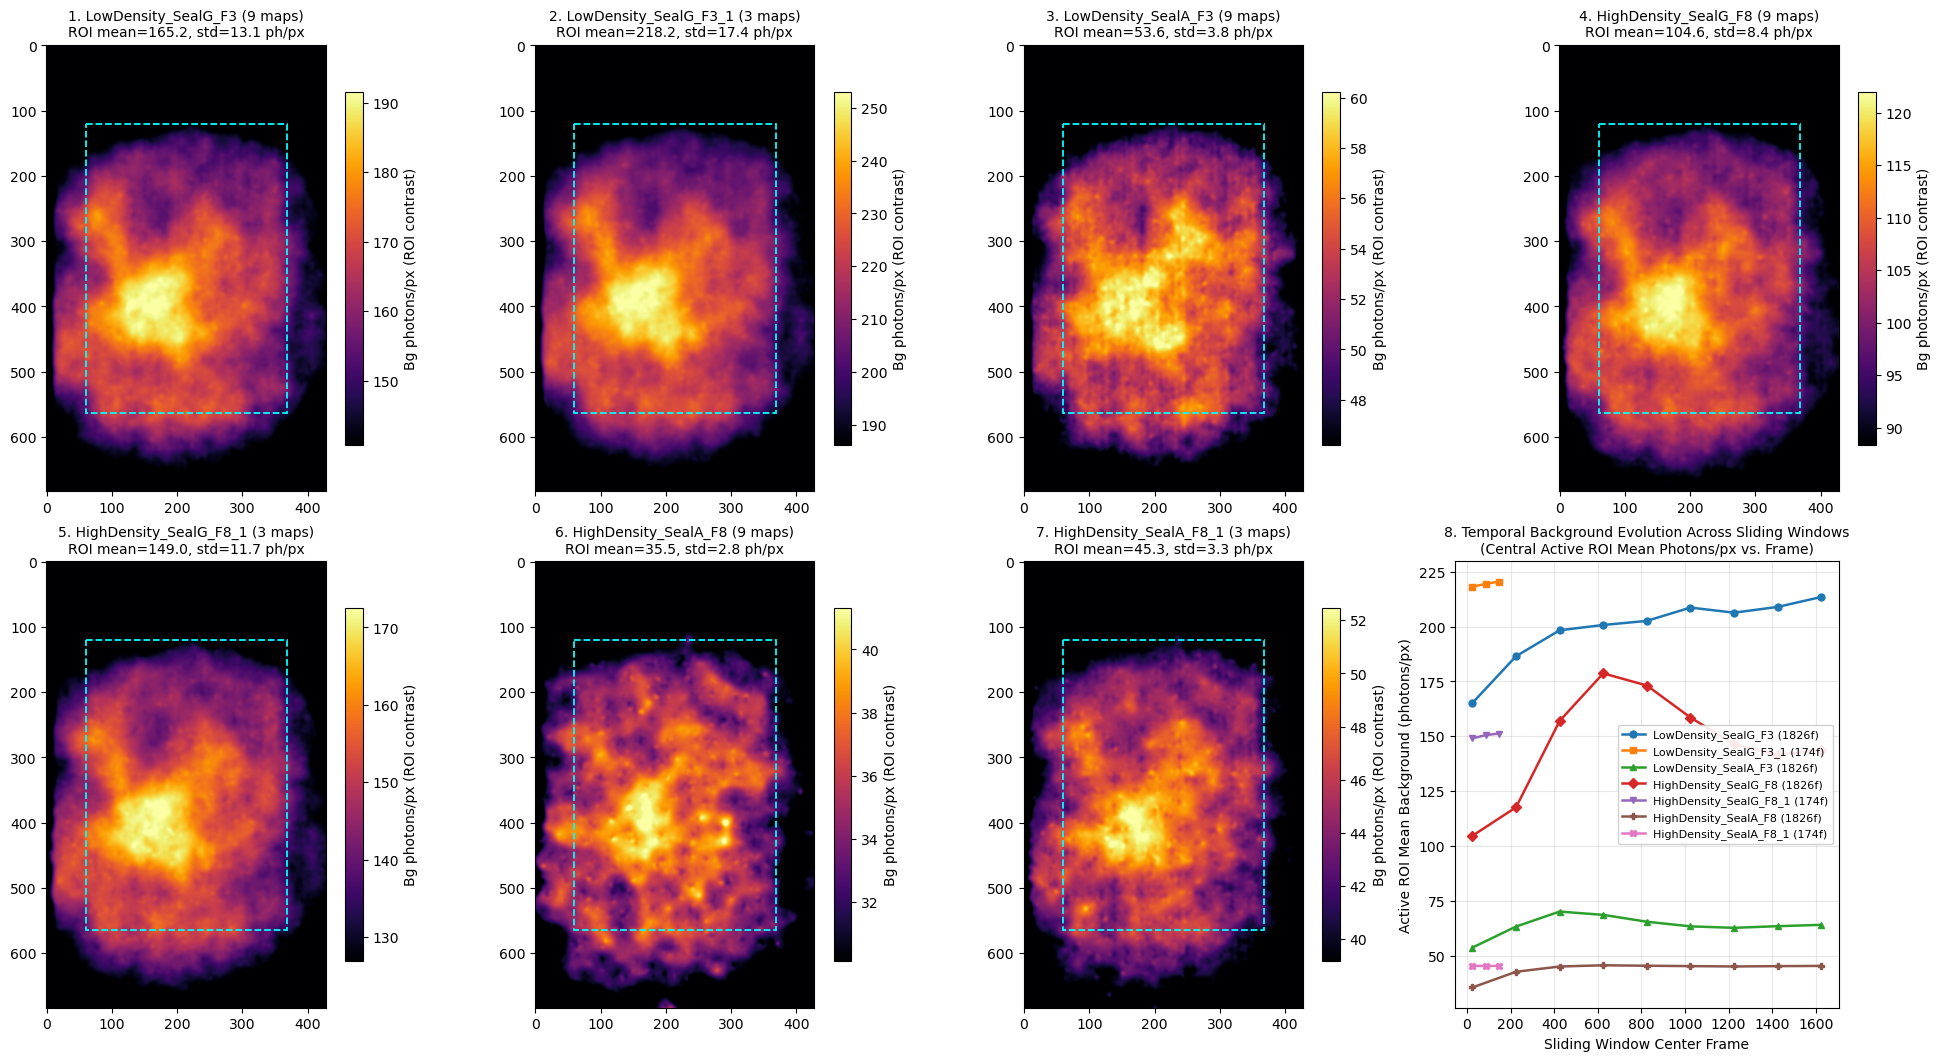

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10.5), constrained_layout=True)
ax_list = axes.ravel()

# Plot 1 representative full-FOV noise map (f0000_to_f0050) for each of the 7 TIFF datasets
for idx, ds in enumerate(TIFF_DATASETS):
    ds_items = [m for m in manifest if m['dataset_id'] == ds['id']]
    item0 = ds_items[0]
    bg_map = np.load(noise_maps_dir / item0['filename'], mmap_mode='r')
    roi = bg_map[120:564, 60:368]
    vmin_r, vmax_r = np.percentile(roi, [5, 99.5])

    ax = ax_list[idx]
    im = ax.imshow(bg_map, cmap='inferno', vmin=vmin_r, vmax=vmax_r)
    # Draw dashed box indicating central active illumination ROI [y: 120..564, x: 60..368]
    rect = mpatches.Rectangle((60, 120), 308, 444, fill=False, edgecolor='cyan', linewidth=1.3, linestyle='--')
    ax.add_patch(rect)
    ax.set_title(
        f"{idx+1}. {ds['id']} ({len(ds_items)} maps)\n"
        f"ROI mean={item0['roi_mean']:.1f}, std={item0['roi_std']:.1f} ph/px",
        fontsize=10
    )
    fig.colorbar(im, ax=ax, label='Bg photons/px (ROI contrast)', fraction=0.046)

# Panel 8 (Bottom-Right): Temporal evolution of ROI background mean across frames for all 7 datasets
ax_t = ax_list[7]
markers = ['o', 's', '^', 'D', 'v', 'P', 'X']
for idx, ds in enumerate(TIFF_DATASETS):
    ds_items = sorted([m for m in manifest if m['dataset_id'] == ds['id']], key=lambda x: x['center_frame'])
    t_centers = [m['center_frame'] for m in ds_items]
    r_means = [m['roi_mean'] for m in ds_items]
    ax_t.plot(t_centers, r_means, marker=markers[idx % len(markers)], linewidth=1.8, markersize=5, label=f"{ds['id']} ({ds['n_frames']}f)")

ax_t.set_title('8. Temporal Background Evolution Across Sliding Windows\n(Central Active ROI Mean Photons/px vs. Frame)', fontsize=10)
ax_t.set_xlabel('Sliding Window Center Frame')
ax_t.set_ylabel('Active ROI Mean Background (photons/px)')
ax_t.grid(True, alpha=0.3)
ax_t.legend(fontsize=8, loc='center right', framealpha=0.9)
plt.show()

## 3. Memory-Mapped 3-Stage Augmentation Engine (`BackgroundPatchAugmentor`)

Using the disk-cached `.npy` maps in `localisation_workflow/vae_background/noise_maps/`, `BackgroundPatchAugmentor` generates an unlimited stream of physically realistic $P \times P$ background patches (default $P = 100$ or $64$) without loading the entire noise-map library into memory:

1. **Single-Map Spatial Sampling + Geometric Warp (`sample_single_augmented_patch`):**
   - Randomly selects a noise map from `manifest.json` and opens it with `np.load(..., mmap_mode='r')`.
   - Samples a crop center $(y_c, x_c)$ inside the active central illumination region ($y_c \in [150, 534],\; x_c \in [100, 328]$) so expanded source crops stay clear of the dark optical vignette boundaries.
   - **Coin-Flip Horizontal Reflection ($p = 0.5$) + Continuous Rotation ($\theta \sim \mathcal{U}(0^\circ, 360^\circ)$)** inside a $\lceil \sqrt{2}\,P \rceil \times \lceil \sqrt{2}\,P \rceil$ source window.
   - **Anisotropic Affine Warp** (stretch $s_x, s_y \sim \mathcal{U}(0.75, 1.35)$ and shear $\psi_x, \psi_y \sim \mathcal{U}(-15^\circ, +15^\circ)$) inside an oversized source window before center-cropping to $P \times P$.
2. **Normalised Convex Combination of $K$ Augmented Patches (`sample_patch`):**
   - Draws $K$ independently warped patches $\{B_k(y, x)\}_{k=1}^K$ with Dirichlet weights $\boldsymbol{\lambda} \sim \operatorname{Dirichlet}(\mathbf{1}_K)$ ($\sum_{k=1}^K \lambda_k = 1$).
   - Normalises each patch to zero-mean and unit-variance first ($\hat{B}_k = (B_k - \mu_k)/\sigma_k$), forms the convex combination $\sum_{k=1}^K \lambda_k \hat{B}_k$, re-normalises to unit variance so mixing never flattens spatial contrast, and scales back up to physical photon units $B_{\mathrm{phys}}(y, x) = \max(\mu_{\mathrm{target}} + \sigma_{\mathrm{target}} \hat{B}_{\mathrm{mix}}(y, x),\; 1.0)$.

In [5]:
class BackgroundPatchAugmentor(decode.simulation.background.Background):
    """
    Disk-backed 3-Stage Background Patch Augmentor compatible with both standalone patch sampling
    (for VAE training / inspection) and DECODE's `decode.simulation.background.Background` interface.
    """

    def __init__(
        self,
        manifest_list: list,
        maps_dir: Path = noise_maps_dir,
        patch_size: int = 100,
        enable_rotation: bool = True,
        enable_affine: bool = True,
        stretch_range: tuple = (0.75, 1.35),
        shear_deg_range: tuple = (-15.0, 15.0),
        max_convex_k: int = 2,
        density_filter: str = None,
        seal_filter: str = None,
        forward_return: str = None,
    ):
        super().__init__(forward_return=forward_return)
        self.maps_dir = Path(maps_dir)
        self.patch_size = patch_size
        self.enable_rotation = enable_rotation
        self.enable_affine = enable_affine
        self.stretch_range = stretch_range
        self.shear_deg_range = shear_deg_range
        self.max_convex_k = max_convex_k

        filtered = manifest_list
        if density_filter is not None:
            filtered = [m for m in filtered if m['density'] == density_filter]
        if seal_filter is not None:
            filtered = [m for m in filtered if m['seal'] == seal_filter]
        assert len(filtered) > 0, 'No noise maps matched the specified filter!'
        self.manifest = filtered

    def sample_single_warped_patch(
        self,
        P: int = None,
        map_idx: int = None,
        cy: int = None,
        cx: int = None,
        apply_rot: bool = None,
        apply_aff: bool = None,
        rng: np.random.Generator = None,
    ):
        if P is None:
            P = self.patch_size
        if rng is None:
            rng = np.random.default_rng()
        if map_idx is None:
            map_idx = int(rng.integers(0, len(self.manifest)))
        if apply_rot is None:
            apply_rot = self.enable_rotation
        if apply_aff is None:
            apply_aff = self.enable_affine

        item = self.manifest[map_idx]
        # Memory-map the .npy file so only the cropped slice is read from disk
        bg_mmap = np.load(self.maps_dir / item['filename'], mmap_mode='r')
        H, W = bg_mmap.shape

        # Oversized source window to accommodate both sqrt(2) rotation and affine stretch/shear without padding
        P_src = int(np.ceil(P * 1.80)) if apply_aff else (int(np.ceil(P * np.sqrt(2))) if apply_rot else P)
        if P_src % 2 != P % 2:
            P_src += 1
        half_s = P_src // 2

        # Sample center across valid FOV bounds (spanning both flat central plateaus and steeper illumination gradients)
        y_min, y_max = half_s, H - half_s
        x_min, x_max = half_s, W - half_s
        if cy is None:
            cy = int(rng.integers(y_min, y_max + 1))
        else:
            cy = int(np.clip(cy, y_min, y_max))
        if cx is None:
            cx = int(rng.integers(x_min, x_max + 1))
        else:
            cx = int(np.clip(cx, x_min, x_max))

        work = np.array(bg_mmap[cy - half_s : cy + half_s, cx - half_s : cx + half_s], dtype=np.float32, copy=True)
        meta = {'dataset_id': item['dataset_id'], 'center_frame': item['center_frame'], 'cy': cy, 'cx': cx}

        # Stage 1: Coin-flip horizontal reflection + continuous rotation
        if apply_rot:
            flipped = bool(rng.random() < 0.5)
            if flipped:
                work = np.fliplr(work)
            theta = float(rng.uniform(0.0, 360.0))
            work = rotate(work, angle=theta, reshape=False, order=3, mode='nearest')
            meta['flipped'] = flipped
            meta['theta_deg'] = round(theta, 1)

        # Stage 2: Anisotropic affine warp (stretch s_x, s_y + shear psi_x, psi_y)
        if apply_aff:
            s_y = float(rng.uniform(*self.stretch_range))
            s_x = float(rng.uniform(*self.stretch_range))
            psi_y = float(rng.uniform(*self.shear_deg_range))
            psi_x = float(rng.uniform(*self.shear_deg_range))
            A_fwd = np.array([
                [s_y, np.tan(np.deg2rad(psi_x))],
                [np.tan(np.deg2rad(psi_y)), s_x]
            ], dtype=np.float64)
            A_inv = np.linalg.inv(A_fwd)
            c_vec = np.array([half_s, half_s], dtype=np.float64)
            offset = c_vec - A_inv @ c_vec
            work = affine_transform(work, matrix=A_inv, offset=offset, order=3, mode='nearest')
            meta['s_x'], meta['s_y'] = round(s_x, 2), round(s_y, 2)
            meta['psi_x'], meta['psi_y'] = round(psi_x, 1), round(psi_y, 1)

        # Final center-crop to P x P (zero black padding)
        patch = work[half_s - P // 2 : half_s + P // 2, half_s - P // 2 : half_s + P // 2].copy()
        return patch.astype(np.float32), meta

    def sample_patch(self, P: int = None, k_mix: int = None, rng: np.random.Generator = None):
        """
        Samples an augmented P x P patch using Stage 1 (Flip+Rotate), Stage 2 (Affine Warp),
        and Stage 3 (Normalised Convex Combination of K patches -> physical photon re-scaling).
        Returns (patch_phys, patch_norm, info_dict).
        """
        if P is None:
            P = self.patch_size
        if rng is None:
            rng = np.random.default_rng()
        if k_mix is None:
            k_mix = int(rng.integers(1, self.max_convex_k + 1))

        if k_mix == 1:
            patch_phys, meta = self.sample_single_warped_patch(P=P, rng=rng)
            mu, sig = float(patch_phys.mean()), float(patch_phys.std() + 1e-6)
            patch_norm = (patch_phys - mu) / sig
            meta['k_mix'] = 1
            meta['weights'] = [1.0]
            return patch_phys, patch_norm.astype(np.float32), meta

        weights = rng.dirichlet(np.ones(k_mix, dtype=np.float64)).astype(np.float32)
        norm_components = []
        means, stds, metas = [], [], []
        for _ in range(k_mix):
            p_k, m_k = self.sample_single_warped_patch(P=P, rng=rng)
            mu_k = float(p_k.mean())
            sig_k = float(p_k.std() + 1e-6)
            norm_components.append((p_k - mu_k) / sig_k)
            means.append(mu_k)
            stds.append(sig_k)
            metas.append(m_k)

        # Convex combination in zero-mean, unit-variance shape space + variance-preserving re-normalisation
        mix_norm = sum(w * nc for w, nc in zip(weights, norm_components))
        mix_norm = mix_norm / float(mix_norm.std() + 1e-6)

        # Scale back up to physical photon units
        mu_target = sum(float(w) * m for w, m in zip(weights, means))
        sig_target = sum(float(w) * s for w, s in zip(weights, stds))
        patch_phys = np.maximum(mu_target + sig_target * mix_norm, 1.0).astype(np.float32)

        info = {
            'k_mix': k_mix,
            'weights': [round(float(w), 2) for w in weights],
            'components': metas,
            'mu_target': round(mu_target, 1),
            'sig_target': round(sig_target, 1),
        }
        return patch_phys, mix_norm.astype(np.float32), info

    def sample(self, size: torch.Size, device=torch.device('cpu')) -> torch.Tensor:
        """DECODE Background.sample(size, device) interface."""
        target_h, target_w = size[-2], size[-1]
        assert target_h == target_w, 'BackgroundPatchAugmentor expects square patch size P x P'
        batch_shape = size[:-2]
        n_samples = int(np.prod(batch_shape)) if len(batch_shape) > 0 else 1
        patches = [
            torch.from_numpy(self.sample_patch(P=target_h)[0]) for _ in range(n_samples)
        ]
        return torch.stack(patches, dim=0).reshape(size).to(device)


augmentor = BackgroundPatchAugmentor(manifest, patch_size=100, max_convex_k=2)
print(f'BackgroundPatchAugmentor initialised with {len(augmentor.manifest)} disk-backed noise maps.')

BackgroundPatchAugmentor initialised with 45 disk-backed noise maps.


## 4. End-to-End Pipeline Verification: Disk Noise Maps $\rightarrow$ Augmented Patches $\rightarrow$ Normalised VAE Inputs $\rightarrow$ DECODE Simulations

To verify that the entire pipeline is in order, we generate 5 distinct $100 \times 100$ columns from `BackgroundPatchAugmentor` and pass each augmented physical background map directly into DECODE's 3D spline PSF simulator:
- **Row 1 (Physical Augmented Smooth Background $B_{\mathrm{phys}}(y, x)$):** Shows the $100 \times 100$ background patch in physical photon units (`photons/px`) across individual stages and multi-map convex combinations (including cross-regime `SealG + SealA` mixing).
- **Row 2 (Zero-Mean, Unit-Variance Normalised Shape $\hat{B}(y, x)$):** Shows the exact normalised spatial shape ($\mu = 0,\; \sigma = 1$) that is mixed during convex combinations and will serve as the standardised input tensor for our Variational Autoencoder (VAE).
- **Row 3 (DECODE 3D Spline PSF Simulated $100 \times 100$ Frame):** Shows the resulting noisy SMLM frame generated by DECODE using each augmented background patch, adhering to our **Section 5 / Section 8 Consistency Checklist** (`emitter_av = 58.0` for $100 \times 100$, shared display contrast anchored to `[bg_mean - 65, bg_mean + 75]` photons/px so the full $\sim 3.5 \times 3.5\text{ px}$ PSF footprint is rendered accurately across both high-background `SealG` and low-background `SealA` patches).

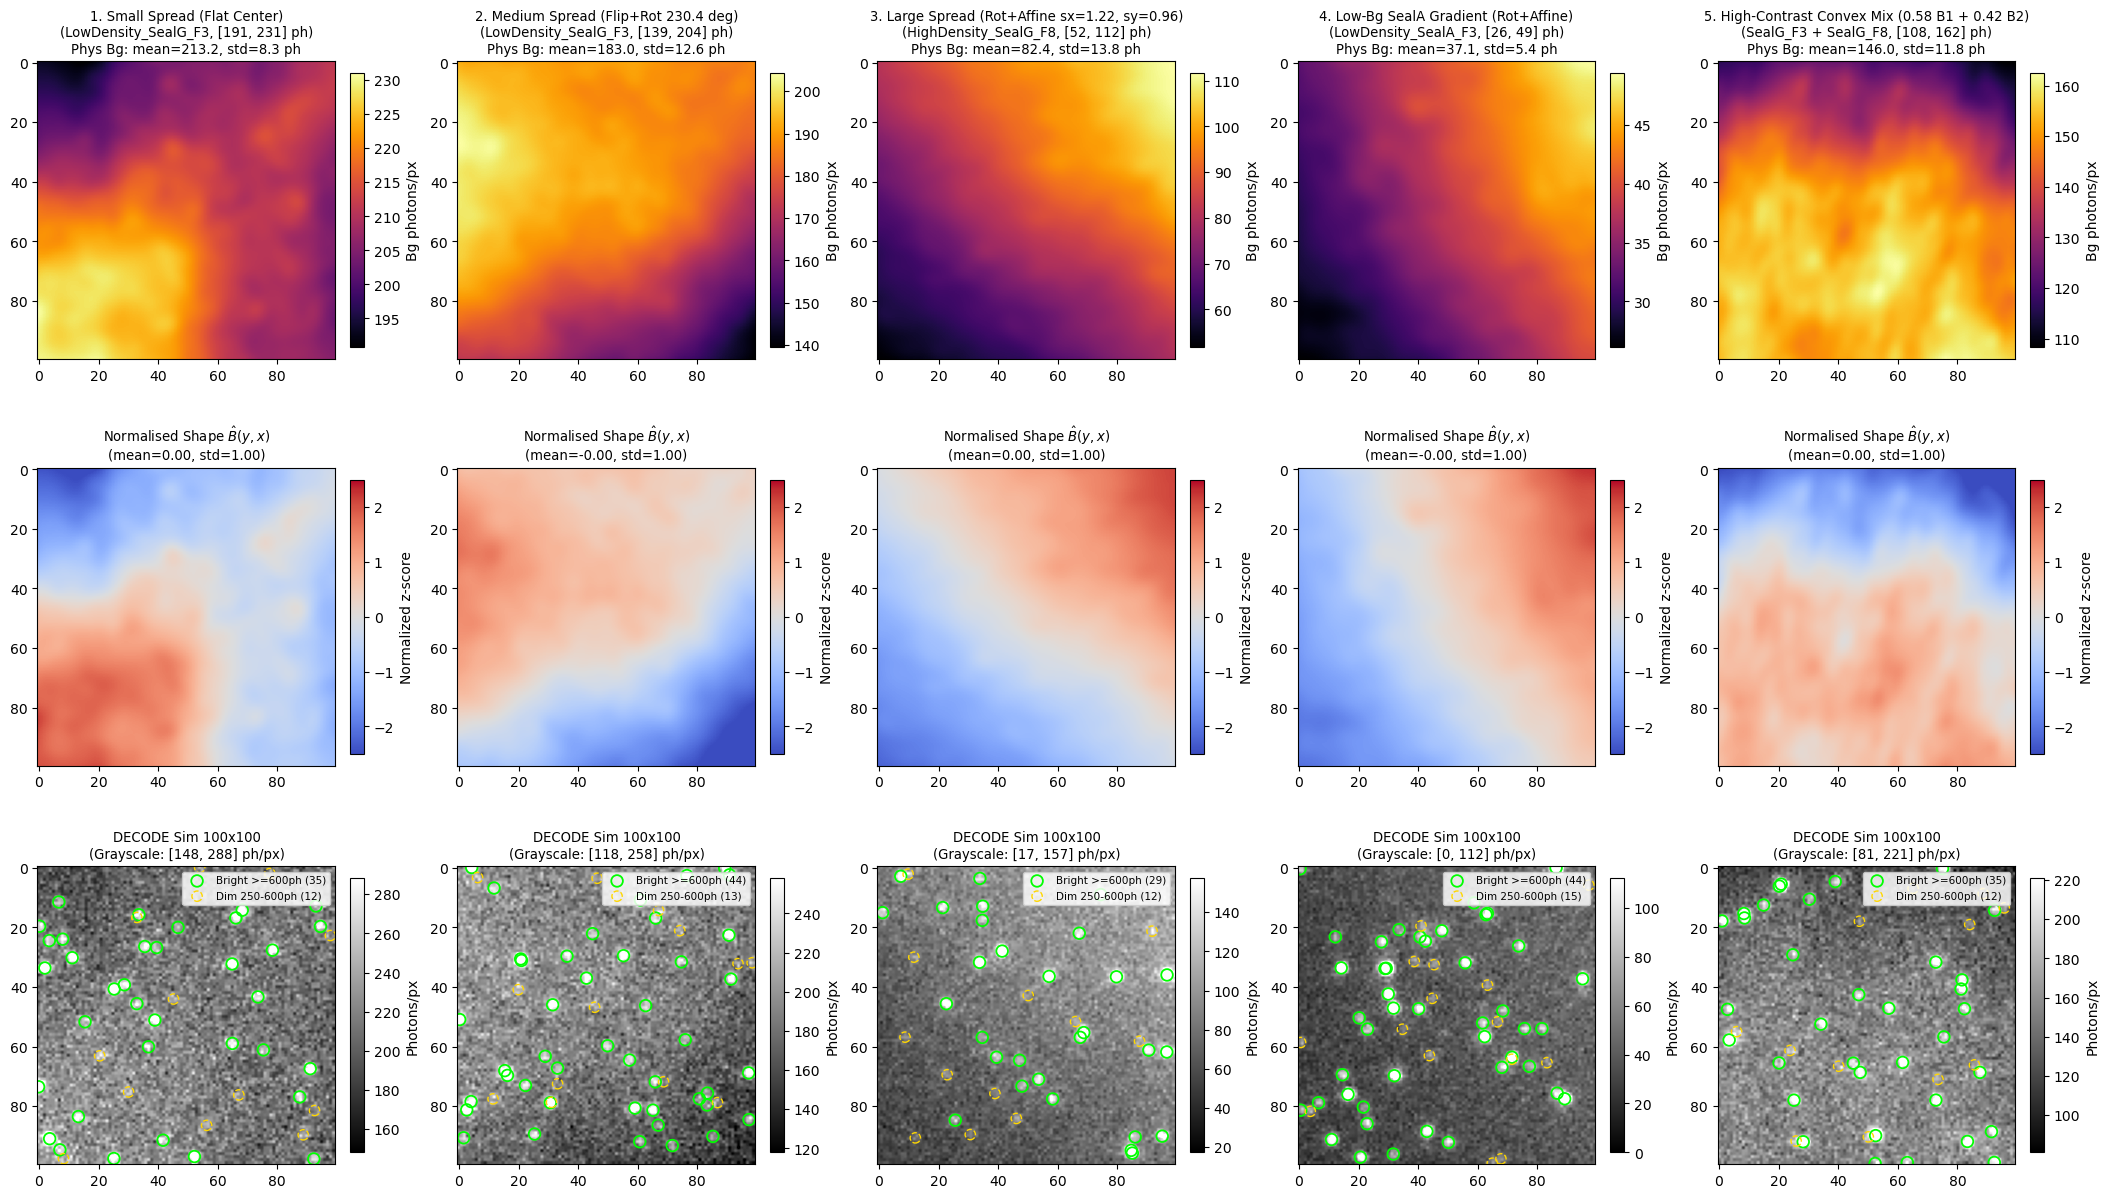

In [6]:
rng_demo = np.random.default_rng(2026)
P = 100

# Create 5 diagnostic samples spanning a varied range of [min, max] spatial contrast:
# 1. Small [min, max] spread (Flat central plateau crop, LowDensity_SealG_F3)
p1_phys, m1 = augmentor.sample_single_warped_patch(P=P, map_idx=2, cy=340, cx=214, apply_rot=False, apply_aff=False, rng=rng_demo)
p1_norm = (p1_phys - p1_phys.mean()) / (p1_phys.std() + 1e-6)

# 2. Medium [min, max] spread (Mid-FOV gradient + Flip/Rotation, LowDensity_SealG_F3)
p2_phys, m2 = augmentor.sample_single_warped_patch(P=P, map_idx=2, cy=180, cx=125, apply_rot=True, apply_aff=False, rng=rng_demo)
p2_norm = (p2_phys - p2_phys.mean()) / (p2_phys.std() + 1e-6)

# 3. Large [min, max] spread (Steep outer illumination gradient + Rot + Affine Warp, HighDensity_SealG_F8)
idx_f8 = next(i for i, m in enumerate(manifest) if m['dataset_id'] == 'HighDensity_SealG_F8' and m['start_frame'] == 200)
p3_phys, m3 = augmentor.sample_single_warped_patch(P=P, map_idx=idx_f8, cy=115, cx=105, apply_rot=True, apply_aff=True, rng=rng_demo)
p3_norm = (p3_phys - p3_phys.mean()) / (p3_phys.std() + 1e-6)

# 4. Low-Background SealA with visible gradient (Outer slope + Rot + Affine Warp, LowDensity_SealA_F3)
idx_seala = next(i for i, m in enumerate(manifest) if m['dataset_id'] == 'LowDensity_SealA_F3')
p4_phys, m4 = augmentor.sample_single_warped_patch(P=P, map_idx=idx_seala, cy=110, cx=105, apply_rot=True, apply_aff=True, rng=rng_demo)
p4_norm = (p4_phys - p4_phys.mean()) / (p4_phys.std() + 1e-6)

# 5. High-Contrast Normalised Convex Mix (K=2) combining two structured gradient patches
pa, ma = augmentor.sample_single_warped_patch(P=P, map_idx=2, cy=155, cx=115, apply_rot=True, apply_aff=True, rng=rng_demo)
pb, mb = augmentor.sample_single_warped_patch(P=P, map_idx=idx_f8, cy=540, cx=310, apply_rot=True, apply_aff=True, rng=rng_demo)
w_a, w_b = 0.58, 0.42
na = (pa - pa.mean()) / (pa.std() + 1e-6)
nb_p = (pb - pb.mean()) / (pb.std() + 1e-6)
p5_norm = w_a * na + w_b * nb_p
p5_norm = (p5_norm / (p5_norm.std() + 1e-6)).astype(np.float32)
mu_5 = w_a * float(pa.mean()) + w_b * float(pb.mean())
sig_5 = w_a * float(pa.std()) + w_b * float(pb.std())
p5_phys = np.maximum(mu_5 + sig_5 * p5_norm, 1.0).astype(np.float32)

demo_samples = [
    (f"1. Small Spread (Flat Center)\n({m1['dataset_id']}, [{p1_phys.min():.0f}, {p1_phys.max():.0f}] ph)", p1_phys, p1_norm),
    (f"2. Medium Spread (Flip+Rot {m2['theta_deg']} deg)\n({m2['dataset_id']}, [{p2_phys.min():.0f}, {p2_phys.max():.0f}] ph)", p2_phys, p2_norm),
    (f"3. Large Spread (Rot+Affine sx={m3['s_x']}, sy={m3['s_y']})\n({m3['dataset_id']}, [{p3_phys.min():.0f}, {p3_phys.max():.0f}] ph)", p3_phys, p3_norm),
    (f"4. Low-Bg SealA Gradient (Rot+Affine)\n({m4['dataset_id']}, [{p4_phys.min():.0f}, {p4_phys.max():.0f}] ph)", p4_phys, p4_norm),
    (f"5. High-Contrast Convex Mix (0.58 B1 + 0.42 B2)\n(SealG_F3 + SealG_F8, [{p5_phys.min():.0f}, {p5_phys.max():.0f}] ph)", p5_phys, p5_norm),
]

# Configure DECODE 3D Spline PSF simulator for P=100 using Section 5 / Section 8 consistency rules
own_cal_path = project / 'data/bead_calibration/Beadzstack_3DLens_3dcal.mat'
p_sim = decode.utils.param_io.load_params(str(project / 'experimental_data_workflow' / 'param_run.yaml'))
p_sim.InOut.calibration_file = str(own_cal_path)
p_sim.Hardware.device = 'cpu'
p_sim.Hardware.device_simulation = 'cpu'
p_sim.Camera.baseline = 400.0
p_sim.Camera.e_per_adu = 0.46
p_sim.Camera.em_gain = None
p_sim.Camera.qe = 0.8
p_sim.Camera.read_sigma = 1.6
p_sim.Camera.spur_noise = 0.0
p_sim.Camera.px_size = [117.0, 117.0]
p_sim.Camera.convert2photons = True
p_sim.Simulation.mode = 'acquisition'
p_sim.Simulation.img_size = [P, P]
p_sim.Simulation.psf_extent = [[-0.5, P - 0.5], [-0.5, P - 0.5], None]
p_sim.Simulation.emitter_extent = [[-0.5, P - 0.5], [-0.5, P - 0.5], [-200.0, 200.0]]
base_density = 380.0 / (256.0 * 256.0)  # Exact Section 5 density -> 58.0 emitters per 100x100 patch
p_sim.Simulation.emitter_av = round(base_density * P * P, 1)
p_sim.Simulation.intensity_mu_sig = [1800.0, 750.0]
p_sim.Simulation.lifetime_avg = 1.0
p_sim.HyperParameter.pseudo_ds_size = 0
p_sim.TestSet.test_size = 0
p_sim.TestSet.frame_extent = p_sim.Simulation.psf_extent
p_sim.TestSet.img_size = [P, P]

sim_base, _ = setup_random_simulation(p_sim)

fig, axes = plt.subplots(3, 5, figsize=(21, 12.2), constrained_layout=True)
np.random.seed(42)
torch.manual_seed(42)

for col, (title_str, bg_phys, bg_norm) in enumerate(demo_samples):
    # Row 0: Physical Augmented Smooth Background Patch (photons/px)
    im0 = axes[0, col].imshow(bg_phys, cmap='inferno')
    axes[0, col].set_title(f"{title_str}\nPhys Bg: mean={bg_phys.mean():.1f}, std={bg_phys.std():.1f} ph", fontsize=9.5)
    fig.colorbar(im0, ax=axes[0, col], label='Bg photons/px', fraction=0.046)

    # Row 1: Zero-Mean, Unit-Variance Normalised Background Shape (for Convex Mixup & VAE input)
    im1 = axes[1, col].imshow(bg_norm, cmap='coolwarm', vmin=-2.5, vmax=2.5)
    axes[1, col].set_title(f"Normalised Shape $\\hat{{B}}(y,x)$\n(mean={bg_norm.mean():.2f}, std={bg_norm.std():.2f})", fontsize=9.5)
    fig.colorbar(im1, ax=axes[1, col], label='Normalized z-score', fraction=0.046)

    # Row 2: DECODE 3D Spline PSF Simulated 100x100 Frame
    class FixedPatchBackground(decode.simulation.background.Background):
        def __init__(self, patch_2d: np.ndarray):
            super().__init__(forward_return=None)
            self.patch_t = torch.from_numpy(np.asarray(patch_2d, dtype=np.float32))
        def sample(self, size: torch.Size, device=torch.device('cpu')) -> torch.Tensor:
            batch_shape = size[:-2]
            n_s = int(np.prod(batch_shape)) if len(batch_shape) > 0 else 1
            return self.patch_t.unsqueeze(0).repeat(n_s, 1, 1).reshape(size).to(device)

    sim_col = decode.simulation.simulator.Simulation(
        psf=sim_base.psf,
        em_sampler=sim_base.em_sampler,
        background=FixedPatchBackground(bg_phys),
        noise=sim_base.noise,
        frame_range=[0, 0],
    )
    em_c, frames_c, _ = sim_col.sample()
    sim_frame = frames_c[0].detach().cpu().numpy()
    em_f0 = em_c.get_subset_frame(0, 0)

    # Consistent dynamic range [bg_mean - 65, bg_mean + 75] matching Section 5's [138, 277] on a 203 bg
    bg_mu = float(bg_phys.mean())
    vmin_c = max(0.0, bg_mu - 65.0)
    vmax_c = bg_mu + 75.0

    bright_mask = em_f0.phot >= 600.0
    dim_mask = (em_f0.phot >= 250.0) & (em_f0.phot < 600.0)
    xyz_b = em_f0.xyz_px[bright_mask].detach().cpu().numpy()
    xyz_d = em_f0.xyz_px[dim_mask].detach().cpu().numpy()

    im2 = axes[2, col].imshow(sim_frame, cmap='gray', vmin=vmin_c, vmax=vmax_c)
    if len(xyz_b) > 0:
        axes[2, col].scatter(xyz_b[:, 1], xyz_b[:, 0], s=70, facecolors='none', edgecolors='lime', linewidths=1.3, label=f'Bright >=600ph ({len(xyz_b)})')
    if len(xyz_d) > 0:
        axes[2, col].scatter(xyz_d[:, 1], xyz_d[:, 0], s=55, facecolors='none', edgecolors='gold', linewidths=1.0, linestyles='--', label=f'Dim 250-600ph ({len(xyz_d)})')
    axes[2, col].legend(loc='upper right', fontsize=7.5, framealpha=0.85)
    axes[2, col].set_title(f"DECODE Sim 100x100\n(Grayscale: [{vmin_c:.0f}, {vmax_c:.0f}] ph/px)", fontsize=9.5)
    fig.colorbar(im2, ax=axes[2, col], label='Photons/px', fraction=0.046)

plt.show()

## 5. Frozen VAE Background Generator $\rightarrow$ DECODE 3D Spline PSF Simulations

Once `SmoothBgBetaVAE` has been trained in [04_vae_background.ipynb](file:///Users/rohan/Documents/projects/mphys/localisation_workflow/04_vae_background.ipynb) and saved to [bg_vae_64x64.pt](file:///Users/rohan/Documents/projects/mphys/localisation_workflow/vae_background/bg_vae_64x64.pt), we load **only the frozen decoder** here and wrap it in `VAEBackground(decode.simulation.background.Background)`.

For each simulated frame/batch, `VAEBackground.sample()`:
1. Samples $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{d})$ and decodes $\hat{B}_{\mathrm{VAE}} = D_\theta(\mathbf{z})$ in one pure-PyTorch forward pass (zero disk I/O, zero CPU spline interpolation),
2. Re-standardises $\hat{B}_{\mathrm{VAE}}$ to exact $(\mu = 0, \sigma = 1)$,
3. Re-scales to physical photon units $B_{\mathrm{phys}} = \max(\mu_{\mathrm{target}} + \sigma_{\mathrm{target}}\,\hat{B}_{\mathrm{VAE}},\; 1.0)$ using empirical $(\mu_{\mathrm{target}}, \sigma_{\mathrm{target}})$ pairs from `noise_maps/manifest.json`.

Loaded frozen VAE decoder from localisation_workflow/vae_background/bg_vae_64x64.pt (d=32, P=64)


[W NNPACK.cpp:51] Could not initialize NNPACK! Reason: Unsupported hardware.


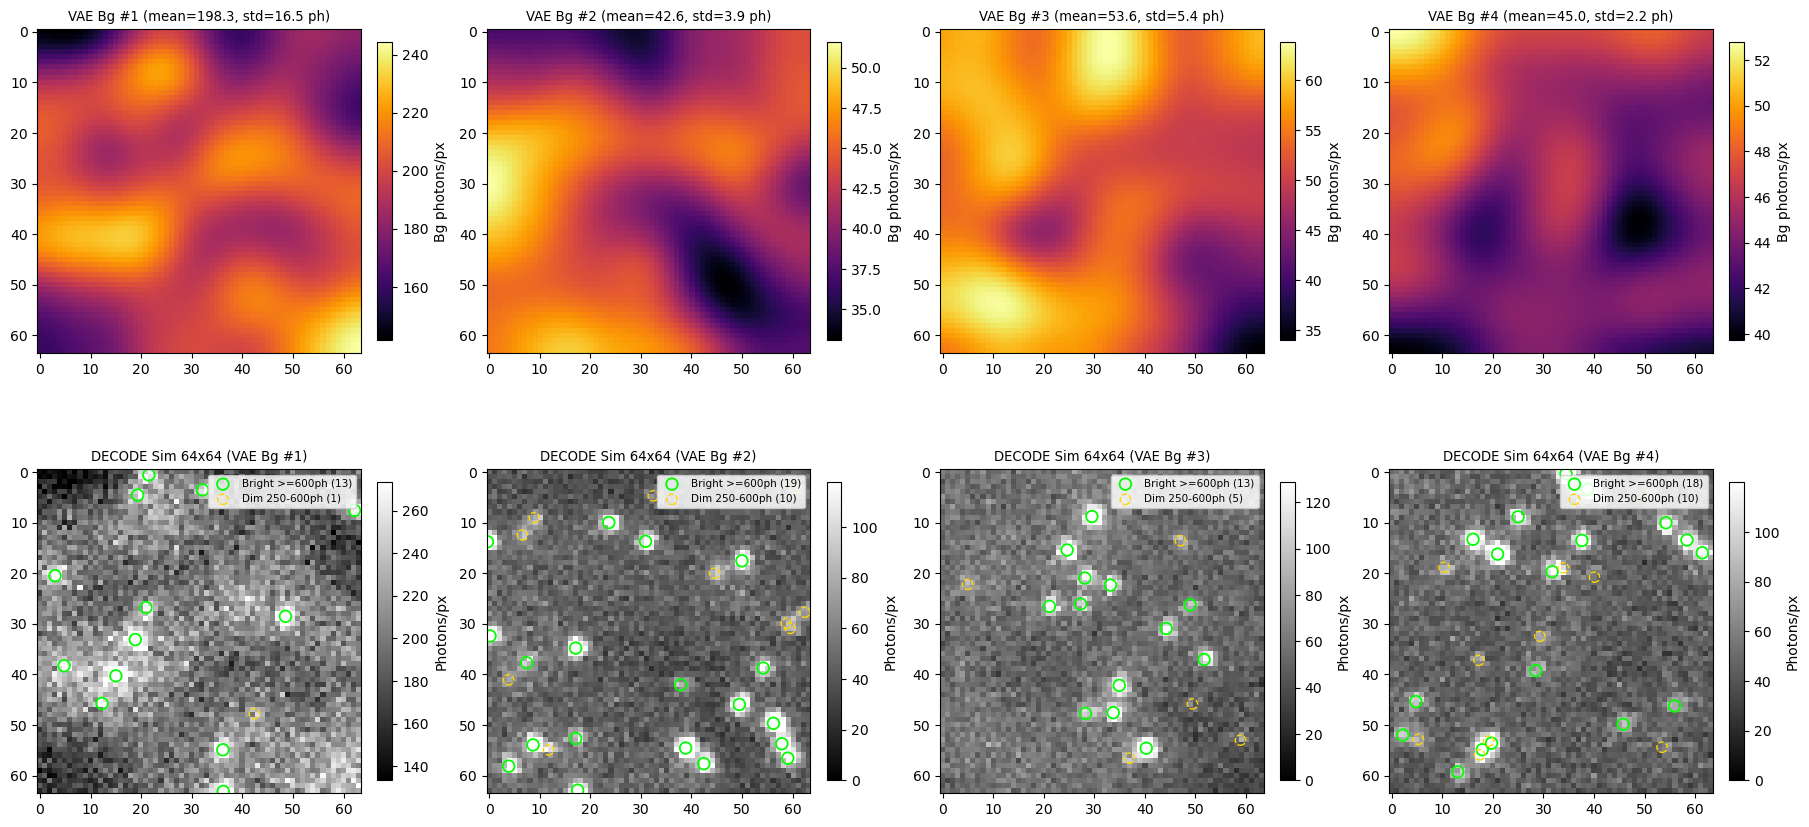

In [7]:
import torch.nn as nn
import torch.nn.functional as F

class SmoothBgBetaVAE(nn.Module):
    def __init__(self, latent_dim: int = 32):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16), nn.SiLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 32), nn.SiLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 64), nn.SiLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 64), nn.SiLU(),
        )
        self.fc_mu = nn.Linear(64 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(64 * 8 * 8, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, 64 * 8 * 8)
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(64, 32, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 32), nn.SiLU(),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(32, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16), nn.SiLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16), nn.SiLU(),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16), nn.SiLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.SiLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1, padding_mode='replicate'),
        )

    def decode(self, z):
        h = F.silu(self.fc_dec(z)).view(-1, 64, 8, 8)
        return self.dec(h)


class VAEBackground(decode.simulation.background.Background):
    """Fast pure-PyTorch DECODE Background sampler powered by the frozen Conv-Beta-VAE decoder."""
    def __init__(self, vae_model: SmoothBgBetaVAE, manifest_list: list, forward_return: str = None):
        super().__init__(forward_return=forward_return)
        self.vae = vae_model.eval()
        for p in self.vae.parameters():
            p.requires_grad_(False)
        self.roi_means = np.array([m['roi_mean'] for m in manifest_list], dtype=np.float32)
        self.roi_stds = np.array([m['roi_std'] for m in manifest_list], dtype=np.float32)

    @torch.no_grad()
    def sample(self, size: torch.Size, device=torch.device('cpu')) -> torch.Tensor:
        target_h, target_w = size[-2], size[-1]
        batch_shape = size[:-2]
        n_samples = int(np.prod(batch_shape)) if len(batch_shape) > 0 else 1
        z = torch.randn(n_samples, self.vae.latent_dim, device=next(self.vae.parameters()).device)
        b_hat = self.vae.decode(z)
        if b_hat.shape[-2:] != (target_h, target_w):
            b_hat = F.interpolate(b_hat, size=(target_h, target_w), mode='bilinear', align_corners=False)
        b_hat = (b_hat - b_hat.mean(dim=(2, 3), keepdim=True)) / (b_hat.std(dim=(2, 3), keepdim=True) + 1e-6)
        idx = np.random.randint(0, len(self.roi_means), size=n_samples)
        mu_t = torch.from_numpy(self.roi_means[idx]).to(b_hat.device).view(n_samples, 1, 1, 1)
        sig_t = torch.from_numpy(self.roi_stds[idx] * np.random.uniform(0.5, 1.5, size=n_samples).astype(np.float32)).to(b_hat.device).view(n_samples, 1, 1, 1)
        b_phys = torch.clamp(mu_t + sig_t * b_hat, min=1.0).squeeze(1)
        return b_phys.reshape(size).to(device)


ckpt_path = workflow_dir / 'vae_background' / 'bg_vae_64x64.pt'
ckpt = torch.load(ckpt_path, map_location='cpu')
vae_loaded = SmoothBgBetaVAE(latent_dim=int(ckpt['latent_dim']))
vae_loaded.load_state_dict(ckpt['model_state'], strict=True)
vae_loaded.eval()
P_vae = int(ckpt.get('patch_size', 64))
print(f'Loaded frozen VAE decoder from {ckpt_path.relative_to(project)} (d={vae_loaded.latent_dim}, P={P_vae})')

p_vae_sim = decode.utils.param_io.load_params(str(project / 'experimental_data_workflow' / 'param_run.yaml'))
p_vae_sim.InOut.calibration_file = str(project / 'data/bead_calibration/Beadzstack_3DLens_3dcal.mat')
p_vae_sim.Hardware.device = 'cpu'
p_vae_sim.Hardware.device_simulation = 'cpu'
p_vae_sim.Camera.baseline = 400.0
p_vae_sim.Camera.e_per_adu = 0.46
p_vae_sim.Camera.em_gain = None
p_vae_sim.Camera.qe = 0.8
p_vae_sim.Camera.read_sigma = 1.6
p_vae_sim.Camera.spur_noise = 0.0
p_vae_sim.Camera.px_size = [117.0, 117.0]
p_vae_sim.Camera.convert2photons = True
p_vae_sim.Simulation.mode = 'acquisition'
p_vae_sim.Simulation.img_size = [P_vae, P_vae]
p_vae_sim.Simulation.psf_extent = [[-0.5, P_vae - 0.5], [-0.5, P_vae - 0.5], None]
p_vae_sim.Simulation.emitter_extent = [[-0.5, P_vae - 0.5], [-0.5, P_vae - 0.5], [-200.0, 200.0]]
p_vae_sim.Simulation.emitter_av = round((380.0 / (256.0 * 256.0)) * P_vae * P_vae, 1)
p_vae_sim.Simulation.intensity_mu_sig = [1800.0, 750.0]
p_vae_sim.Simulation.lifetime_avg = 1.0
p_vae_sim.HyperParameter.pseudo_ds_size = 0
p_vae_sim.TestSet.test_size = 0
p_vae_sim.TestSet.frame_extent = p_vae_sim.Simulation.psf_extent
p_vae_sim.TestSet.img_size = [P_vae, P_vae]

sim_vae_base, _ = setup_random_simulation(p_vae_sim)
sim_vae = decode.simulation.simulator.Simulation(
    psf=sim_vae_base.psf,
    em_sampler=sim_vae_base.em_sampler,
    background=VAEBackground(vae_loaded, manifest),
    noise=sim_vae_base.noise,
    frame_range=[0, 0],
)

fig, axes = plt.subplots(2, 4, figsize=(18, 8.8), constrained_layout=True)
np.random.seed(12)
torch.manual_seed(12)

for col in range(4):
    em_s, frames_s, bg_s = sim_vae.sample()
    bg_np = bg_s[0].detach().cpu().numpy()
    fr_np = frames_s[0].detach().cpu().numpy()
    em_f0 = em_s.get_subset_frame(0, 0)
    im0 = axes[0, col].imshow(bg_np, cmap='inferno')
    axes[0, col].set_title(f'VAE Bg #{col+1} (mean={bg_np.mean():.1f}, std={bg_np.std():.1f} ph)', fontsize=9.5)
    fig.colorbar(im0, ax=axes[0, col], label='Bg photons/px', fraction=0.046)

    bg_mu = float(bg_np.mean())
    vmin_c, vmax_c = max(0.0, bg_mu - 65.0), bg_mu + 75.0
    xyz_b = em_f0.xyz_px[em_f0.phot >= 600.0].detach().cpu().numpy()
    xyz_d = em_f0.xyz_px[(em_f0.phot >= 250.0) & (em_f0.phot < 600.0)].detach().cpu().numpy()
    im1 = axes[1, col].imshow(fr_np, cmap='gray', vmin=vmin_c, vmax=vmax_c)
    if len(xyz_b) > 0:
        axes[1, col].scatter(xyz_b[:, 1], xyz_b[:, 0], s=70, facecolors='none', edgecolors='lime', linewidths=1.3, label=f'Bright >=600ph ({len(xyz_b)})')
    if len(xyz_d) > 0:
        axes[1, col].scatter(xyz_d[:, 1], xyz_d[:, 0], s=55, facecolors='none', edgecolors='gold', linewidths=1.0, linestyles='--', label=f'Dim 250-600ph ({len(xyz_d)})')
    axes[1, col].legend(loc='upper right', fontsize=7.5, framealpha=0.85)
    axes[1, col].set_title(f'DECODE Sim {P_vae}x{P_vae} (VAE Bg #{col+1})', fontsize=9.5)
    fig.colorbar(im1, ax=axes[1, col], label='Photons/px', fraction=0.046)

plt.show()

## 6. Portable `simulation()` Function & 20-Sample Inspection Board

To make the end-to-end simulator portable and ready for DECODE training or standalone evaluation, we encapsulate everything into two self-contained functions:
- `build_vae_decode_simulator(...)`: Loads the 3D spline PSF calibration, ONI Nanoimager sCMOS camera parameters, frozen `SmoothBgBetaVAE` decoder (`bg_vae_64x64.pt`), and `noise_maps/manifest.json` once.
- `simulation(sim_obj, emitter_av_bounds=(12.0, 120.0), ...)`: On every call, draws a **random emitter density** $\lambda \sim \mathcal{U}(\text{min}, \text{max})$ (updating `em_sampler._em_avg` and `_emitter_av_total` in-place with zero PSF reload overhead) and a **fresh VAE background** from $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{32})$, returning `(frames, bg_maps, emitters, target_em_av)`.

Below, we run `simulation()` **20 times** across `emitter_av_bounds = (12.0, 120.0)` (spanning sparse `LowDensity_F3` up to crowded `HighDensity_F8` regimes) and display the full $4 \times 5$ board.

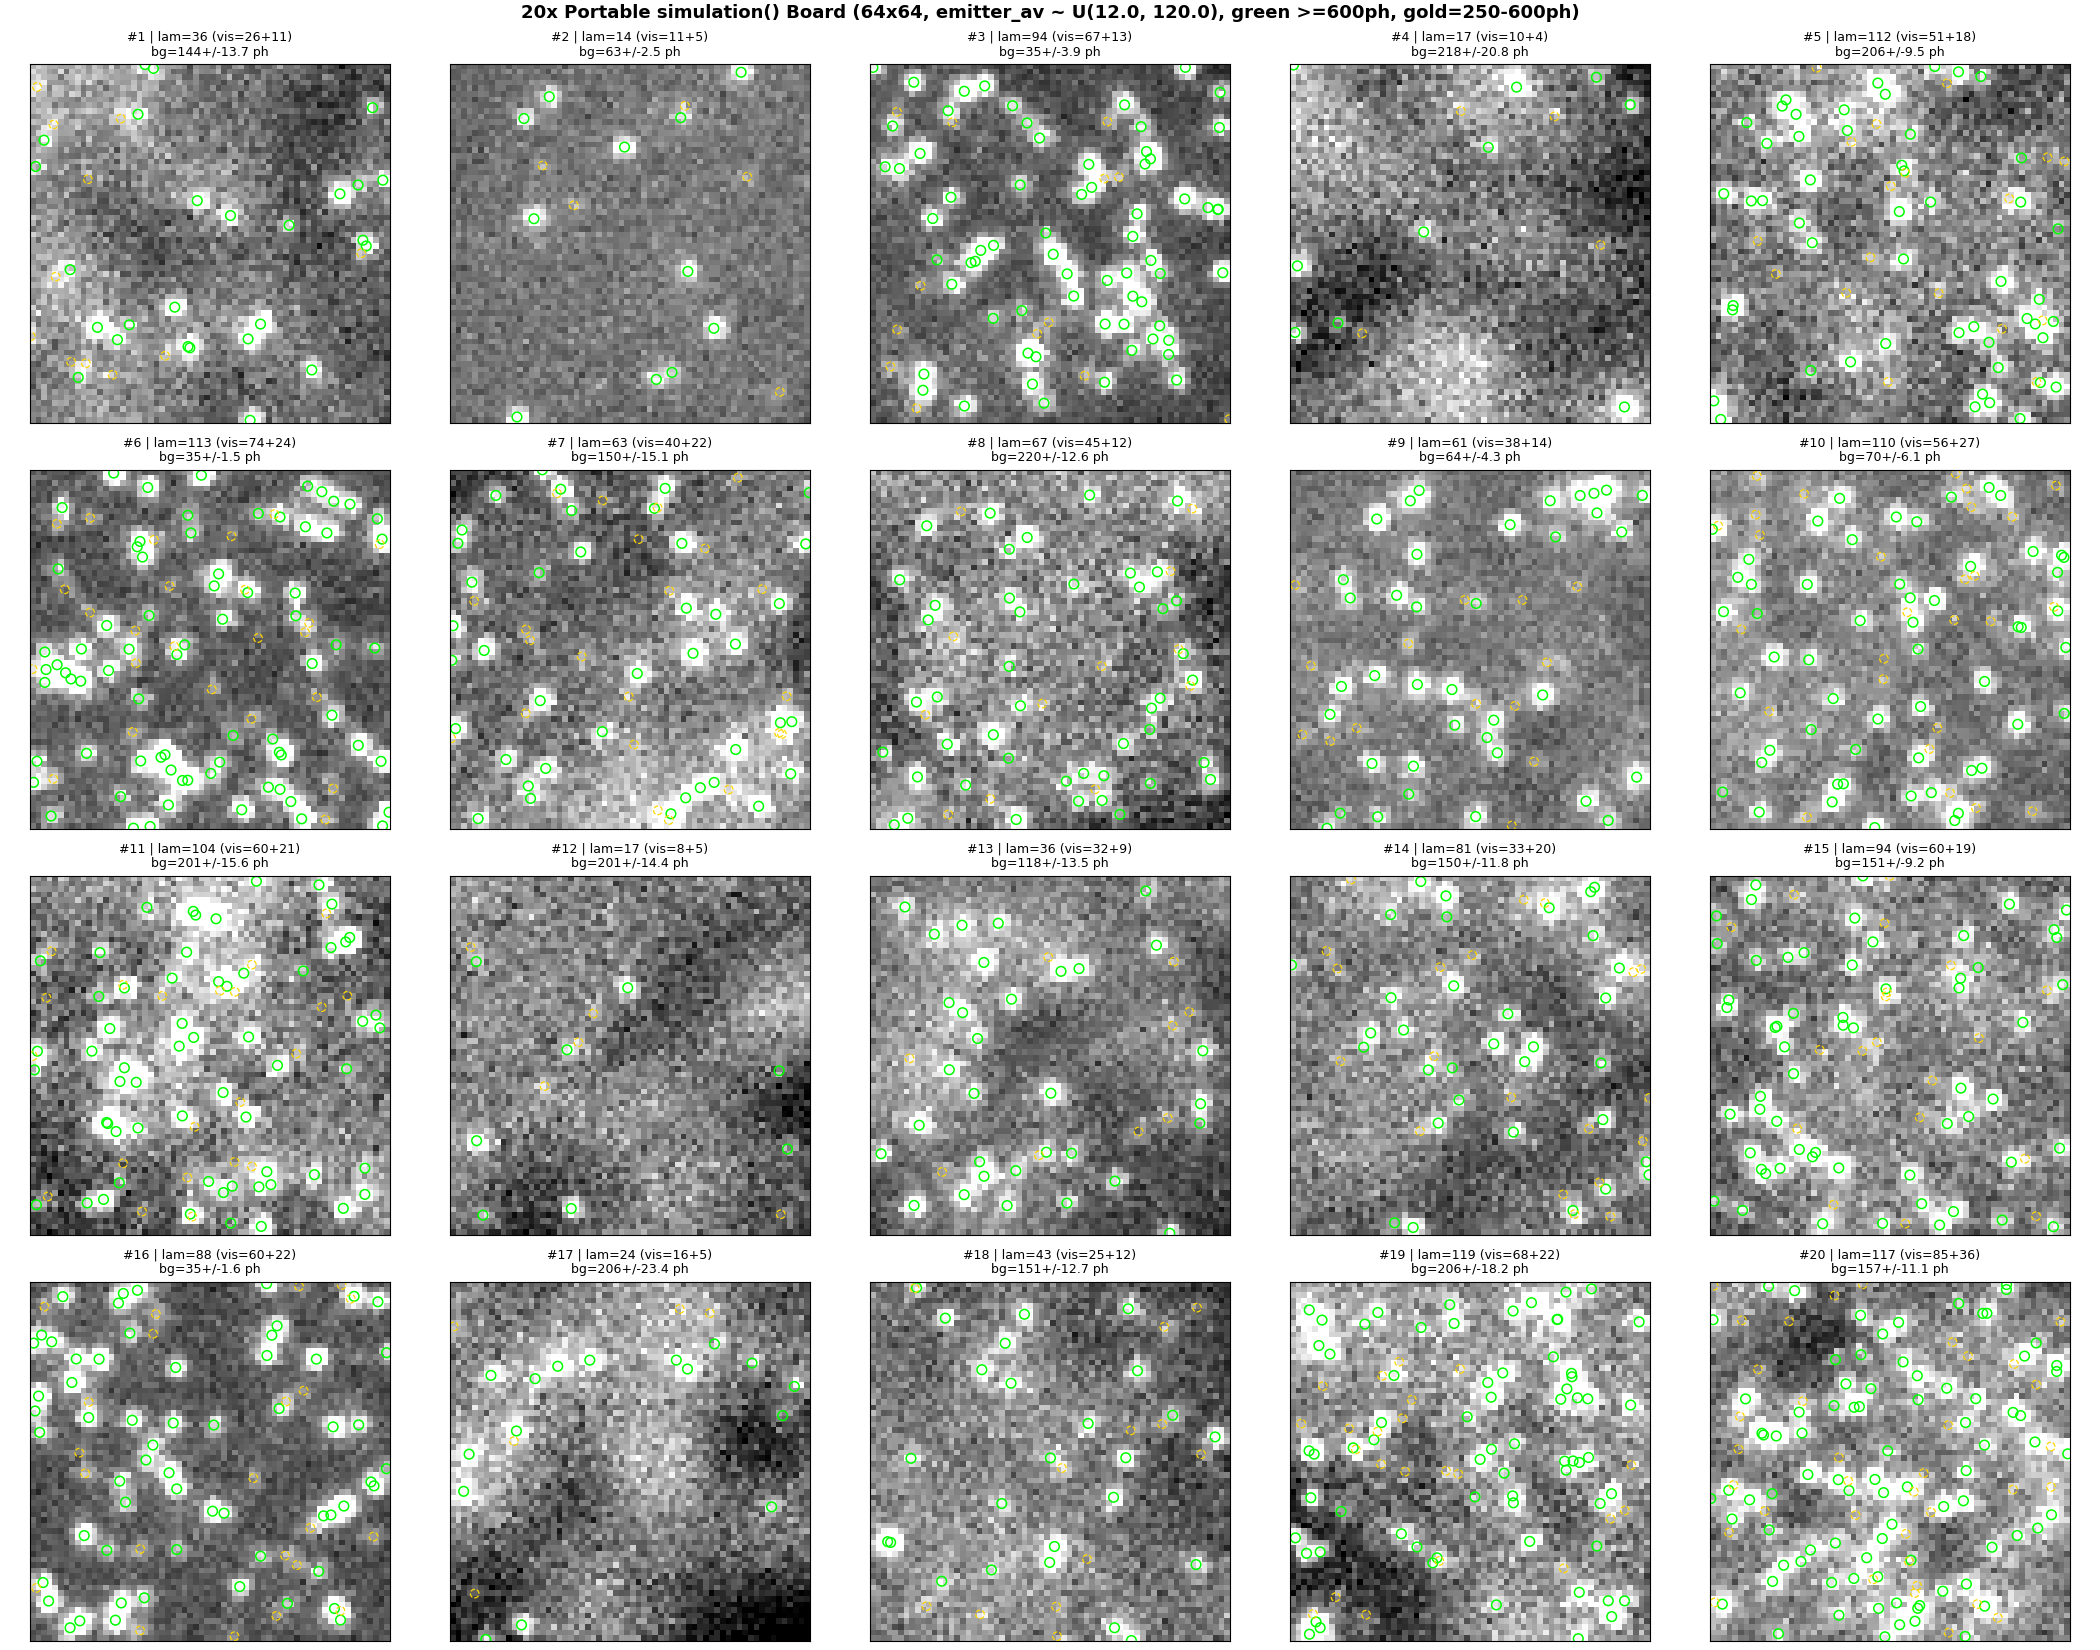

In [7]:
def build_vae_decode_simulator(
    project_dir: Path = project,
    ckpt_rel: str = 'localisation_workflow/vae_background/bg_vae_64x64.pt',
    manifest_rel: str = 'localisation_workflow/vae_background/noise_maps/manifest.json',
    cal_rel: str = 'data/bead_calibration/Beadzstack_3DLens_3dcal.mat',
    param_rel: str = 'experimental_data_workflow/param_run.yaml',
    z_range_nm: tuple = (-200.0, 200.0),
    intensity_mu_sig: tuple = (1800.0, 750.0),
    lifetime_avg: float = 1.0,
    frame_range: tuple = (0, 0),
    device: str = 'cpu',
):
    """
    Portable factory that builds a complete DECODE Simulation powered by our frozen VAE background.
    """
    project_dir = Path(project_dir)
    ckpt = torch.load(project_dir / ckpt_rel, map_location=device)
    vae_m = SmoothBgBetaVAE(latent_dim=int(ckpt['latent_dim'])).to(device)
    vae_m.load_state_dict(ckpt['model_state'], strict=True)
    vae_m.eval()
    P_sz = int(ckpt.get('patch_size', 64))
    manifest_data = json.loads((project_dir / manifest_rel).read_text())

    p = decode.utils.param_io.load_params(str(project_dir / param_rel))
    p.InOut.calibration_file = str(project_dir / cal_rel)
    p.Hardware.device = device
    p.Hardware.device_simulation = device
    p.Camera.baseline = 400.0
    p.Camera.e_per_adu = 0.46
    p.Camera.em_gain = None
    p.Camera.qe = 0.8
    p.Camera.read_sigma = 1.6
    p.Camera.spur_noise = 0.0
    p.Camera.px_size = [117.0, 117.0]
    p.Camera.convert2photons = True
    p.Simulation.mode = 'acquisition'
    p.Simulation.img_size = [P_sz, P_sz]
    p.Simulation.psf_extent = [[-0.5, P_sz - 0.5], [-0.5, P_sz - 0.5], None]
    p.Simulation.emitter_extent = [[-0.5, P_sz - 0.5], [-0.5, P_sz - 0.5], list(z_range_nm)]
    p.Simulation.emitter_av = 24.0
    p.Simulation.intensity_mu_sig = list(intensity_mu_sig)
    p.Simulation.lifetime_avg = lifetime_avg
    p.HyperParameter.pseudo_ds_size = 0
    p.TestSet.test_size = 0
    p.TestSet.frame_extent = p.Simulation.psf_extent
    p.TestSet.img_size = [P_sz, P_sz]

    sim_b, _ = setup_random_simulation(p)
    return decode.simulation.simulator.Simulation(
        psf=sim_b.psf,
        em_sampler=sim_b.em_sampler,
        background=VAEBackground(vae_m, manifest_data),
        noise=sim_b.noise,
        frame_range=list(frame_range),
    )


def simulation(
    sim_obj=None,
    emitter_av_bounds: tuple = (12.0, 120.0),
    seed: int = None,
):
    """
    Portable simulation() call:
      - Samples a random target emitter count lambda ~ Uniform(*emitter_av_bounds)
      - Samples a fresh VAE background patch and simulates 3D PSF + sCMOS Poisson/read noise
    Returns: (frames_tensor, bg_tensor, emitter_set, sampled_em_av)
    """
    if sim_obj is None:
        sim_obj = build_vae_decode_simulator()
    if seed is not None:
        np.random.seed(seed)
        torch.manual_seed(seed)

    target_em_av = float(np.random.uniform(*emitter_av_bounds))
    sim_obj.em_sampler._em_avg = target_em_av
    sim_obj.em_sampler._emitter_av_total = (
        target_em_av * sim_obj.em_sampler._num_frames_plus / (sim_obj.em_sampler.lifetime_avg + 1)
    )

    em_set, frames, bg_maps = sim_obj.sample()
    return frames, bg_maps, em_set, target_em_av


# --- Run simulation() 20 times and display a 4x5 inspection board ---
portable_sim = build_vae_decode_simulator()
EMITTER_BOUNDS = (12.0, 120.0)  # Adjust bounds here (per 64x64 patch)

fig, axes = plt.subplots(4, 5, figsize=(21, 16.5), constrained_layout=True)
np.random.seed(2026)
torch.manual_seed(2026)

for i, ax in enumerate(axes.ravel()):
    frames, bg_maps, em_set, lam_av = simulation(portable_sim, emitter_av_bounds=EMITTER_BOUNDS)
    fr_np = frames[0].detach().cpu().numpy()
    bg_np = bg_maps[0].detach().cpu().numpy()
    em_f0 = em_set.get_subset_frame(0, 0)

    bg_mu = float(bg_np.mean())
    vmin_c, vmax_c = max(0.0, bg_mu - 65.0), bg_mu + 75.0

    xyz_b = em_f0.xyz_px[em_f0.phot >= 600.0].detach().cpu().numpy()
    xyz_d = em_f0.xyz_px[(em_f0.phot >= 250.0) & (em_f0.phot < 600.0)].detach().cpu().numpy()

    ax.imshow(fr_np, cmap='gray', vmin=vmin_c, vmax=vmax_c)
    if len(xyz_b) > 0:
        ax.scatter(xyz_b[:, 1], xyz_b[:, 0], s=48, facecolors='none', edgecolors='lime', linewidths=1.1)
    if len(xyz_d) > 0:
        ax.scatter(xyz_d[:, 1], xyz_d[:, 0], s=38, facecolors='none', edgecolors='gold', linewidths=0.9, linestyles='--')
    ax.set_title(
        f"#{i+1} | lam={lam_av:.0f} (vis={len(xyz_b)}+{len(xyz_d)})\n"
        f"bg={bg_mu:.0f}+/-{bg_np.std():.1f} ph",
        fontsize=9
    )
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(
    f'20x Portable simulation() Board (64x64, emitter_av ~ U{EMITTER_BOUNDS}, green >=600ph, gold=250-600ph)',
    fontsize=13, fontweight='bold'
)
plt.show()